## Load data and stratified train-test split 80% - 20%

First, I load the prepared Ames Housing dataset, which contains 2,930 houses and 333 features. The target variable is `PriceClass`, which represents the six price categories we want to predict.

I split the data into training (80%) and test (20%) sets. I use stratification (`stratify=y`) to make sure that all six price classes are represented in approximately the same proportions in both sets. This is especially important because the classes are imbalanced and some of them have considerably fewer observations.

I use `random_state=42` to make the split reproducible.

The training set will be used for training and cross-validation, while the test set will remain separate and will only be used for the final evaluation.


In [1]:
import xgboost, optuna, plotly
print(xgboost.__version__, optuna.__version__, plotly.__version__)
from lab2_utils import get_data, get_split, CLASS_NAMES

X, y = get_data()
X_train, X_test, y_train, y_test = get_split(X, y)
print("X:", X.shape)
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())


3.4.1 5.0.0 7.1.0
X: (2930, 333)
PriceClass
0    189
1    407
2    830
3    549
4    318
5     51
Name: count, dtype: int64
PriceClass
0     48
1    102
2    207
3    137
4     79
5     13
Name: count, dtype: int64



## 2. Stratified 5-Fold Cross-Validation

To get a better idea of how the model performs on different subsets of the data, I use stratified 5-fold cross-validation on the training set.

The training data is divided into five folds. In each iteration, four folds are used for training and the remaining one for validation. This process is repeated five times, so each fold is used for validation once.

I use **macro-averaged F1-score (macro-F1)** as the evaluation metric because we have six imbalanced price classes. For each fold, the F1-score is calculated separately for all six classes and then averaged, giving every class equal importance regardless of how many houses it contains.

After completing all five iterations, I look at:

- **Individual fold scores:** Macro-F1 obtained in each of the five iterations.
- **Mean macro-F1:** Average of the five fold scores, giving an idea of the model's overall performance.
- **Standard deviation:** Shows how much the scores vary between folds. A lower value means that the model performs more consistently across the different subsets.


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

# Define 5-fold stratified cross-validation
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the baseline model using 5-fold CV
cv_scores = cross_val_score(
    XGBClassifier(random_state=42),
    X_train,
    y_train,
    cv=cv5,
    scoring="f1_macro"
)

print("Individual fold scores:", cv_scores.round(3))
print("Mean macro-F1:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Individual fold scores: [0.752 0.721 0.704 0.737 0.7  ]
Mean macro-F1: 0.722
Standard deviation: 0.02




## 3. Training the Baseline Model and Generating Predictions

After cross-validation, I will train a new XGBoost model using the entire training set (80% of the data). The previous five models were only used to evaluate the performance through cross-validation. Now I want to have one trained model that I can use for the actual evaluation.

After training, I will make predictions on the test set (20% of the data), which the model has not seen before.

I will use two types of predictions:
- `y_pred`: the predicted price class for each house.
- `y_prob`: the predicted probabilities for each of the six price classes.

I need the predicted classes for the evaluation metrics and confusion matrix, while the probabilities will be used for the ROC and Precision-Recall curves and finding the best classification thresholds.


In [3]:
baseline = XGBClassifier(random_state=42)

baseline.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklear

In [4]:
from sklearn.metrics import f1_score

y_pred = baseline.predict(X_test)

test_macro_f1 = f1_score(y_test, y_pred, average="macro")

print("Test macro-F1:", round(test_macro_f1, 3))

Test macro-F1: 0.748



## 4. Evaluation Metrics

Now I want to evaluate how well the model predicts the price classes on the test set. I use the predictions from the baseline model and compare them with the actual price classes.

I calculate the following metrics:

- **Accuracy:** The proportion of houses for which the predicted price class is correct.
- **Precision:** How many of the houses predicted to belong to a certain class actually belong to that class.
- **Recall:** How many of the actual houses in a class were correctly identified by the model.
- **F1-score:** Combines precision and recall into one metric.

Since the dataset is imbalanced, I use macro-averaging for precision, recall and F1. This means that all six price classes have equal importance when calculating the average.

I also look at the individual class scores to see which price categories are more difficult for the model to predict.


In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Generate predictions
y_pred = baseline.predict(X_test)
y_prob = baseline.predict_proba(X_test)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Macro Precision:", round(precision_score(y_test, y_pred, average="macro"), 3))
print("Macro Recall:", round(recall_score(y_test, y_pred, average="macro"), 3))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 3))

# Individual metrics for each price class
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0
))

Accuracy: 0.782
Macro Precision: 0.778
Macro Recall: 0.727
Macro F1: 0.748

Classification Report:
              precision    recall  f1-score   support

       <100k      0.762     0.667     0.711        48
    100–130k      0.676     0.676     0.676       102
    130–180k      0.783     0.855     0.818       207
    180–250k      0.847     0.766     0.805       137
    250–400k      0.819     0.861     0.840        79
       ≥400k      0.778     0.538     0.636        13

    accuracy                          0.782       586
   macro avg      0.778     0.727     0.748       586
weighted avg      0.782     0.782     0.780       586




## 5. Confusion Matrix

Next, I want to see which price classes the model confuses with each other. For this, I create a confusion matrix comparing the actual price classes with the predicted ones.

The confusion matrix has six rows and six columns because we have six possible classes.

- **Rows:** Actual price classes.
- **Columns:** Predicted price classes.
- **Diagonal:** Houses that were classified correctly.
- **Off-diagonal:** Houses that were assigned to the wrong price class.

This should help me see whether the model mainly confuses neighboring price categories or also makes larger classification errors.


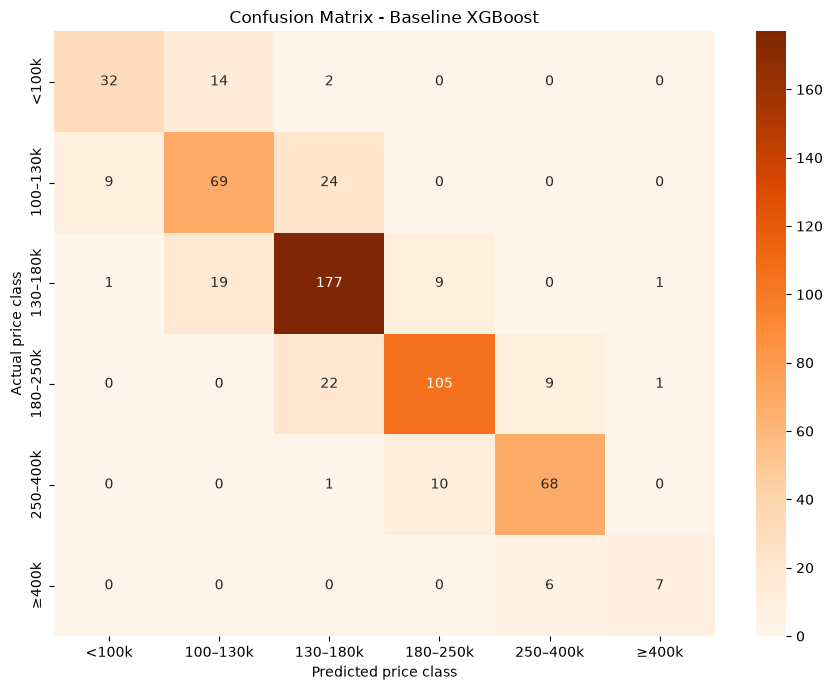

In [6]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(CLASS_NAMES))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted price class")
plt.ylabel("Actual price class")
plt.title("Confusion Matrix - Baseline XGBoost")
plt.tight_layout()
plt.show()


## 6. ROC Curve

I also want to investigate how well the model can distinguish between the different price classes using ROC curves.

Since this is a multiclass classification problem, I use the One-vs-Rest (OvR) approach. This means that I evaluate each price class separately, treating it as the positive class and all the other classes as negative.

For each class, I calculate:
- **True Positive Rate (TPR):** The proportion of actual positive observations correctly identified.
- **False Positive Rate (FPR):** The proportion of negative observations incorrectly classified as positive.
- **AUC:** The area under the ROC curve, which gives an overall measure of how well the model separates the class from the others.

An AUC closer to 1 indicates better class separation, while a value around 0.5 indicates performance similar to random ranking.


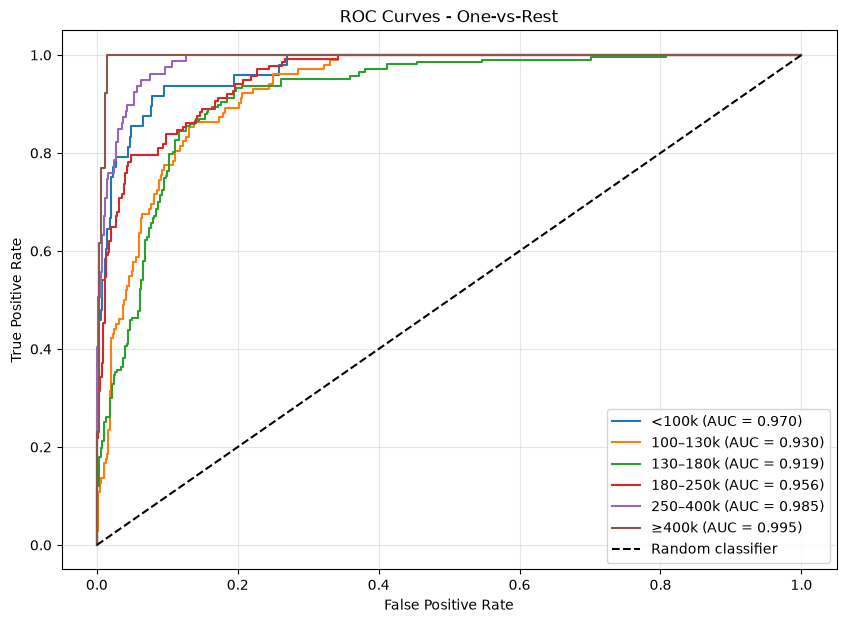

In [7]:
import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Convert the actual classes into binary format (One-vs-Rest)
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(CLASS_NAMES))
)

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - One-vs-Rest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


## 7. Precision-Recall Curve

Besides ROC curves, I use Precision-Recall curves to investigate the model's performance for each price class.

The curves show the relationship between precision and recall at different classification thresholds. I use the same One-vs-Rest approach as with the ROC curves, treating each price class separately.

This is particularly interesting for our dataset because the classes are imbalanced. Precision-Recall curves can give us a better idea of how well the model identifies the smaller classes, especially the ≥400k category.

I also calculate the Average Precision (AP) for each class to summarize the corresponding curve.


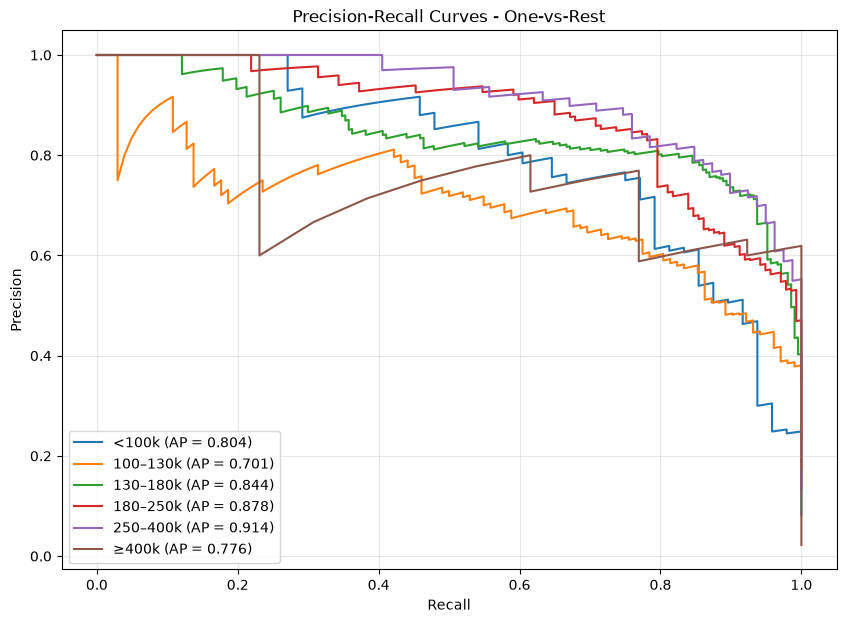

In [8]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(CLASS_NAMES):
    precision, recall, thresholds = precision_recall_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=f"{class_name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - One-vs-Rest")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.show()


## 8. Finding the Best Classification Thresholds

Until now, the model assigns each house to the class with the highest predicted probability. However, this does not necessarily give us the best macro-F1, especially because the price classes are imbalanced.

I want to investigate whether using different thresholds for each class can improve the predictions.

To do this, I first generate out-of-fold probabilities using 5-fold cross-validation. This means that every training observation receives predictions from a model that did not use that observation for training.

I then search for class-specific thresholds that improve the macro-F1 score.

- **Default prediction:** The class with the highest predicted probability.
- **Threshold-adjusted prediction:** The class with the highest probability after accounting for its individual threshold.

I compare the resulting macro-F1 scores to see whether adjusting the thresholds improves the classification.


In [9]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    XGBClassifier(random_state=42),
    X_train,
    y_train,
    cv=cv5,
    method="predict_proba"
)

print("OOF probabilities shape:", oof_prob.shape)

OOF probabilities shape: (2344, 6)


In [10]:
# Function to predict using class-specific thresholds
def predict_with_thresholds(probabilities, thresholds):
    adjusted_scores = probabilities - thresholds
    return np.argmax(adjusted_scores, axis=1)


# Start with equal thresholds (equivalent to normal argmax predictions)
best_thresholds = np.full(len(CLASS_NAMES), 0.5)

best_score = f1_score(
    y_train,
    predict_with_thresholds(oof_prob, best_thresholds),
    average="macro"
)

# Try different threshold values
candidates = np.linspace(0.05, 0.95, 19)

# Adjust one class at a time
for _ in range(3):
    for class_idx in range(len(CLASS_NAMES)):
        for threshold in candidates:
            trial_thresholds = best_thresholds.copy()
            trial_thresholds[class_idx] = threshold

            trial_pred = predict_with_thresholds(
                oof_prob, trial_thresholds
            )

            score = f1_score(
                y_train,
                trial_pred,
                average="macro"
            )

            if score > best_score:
                best_score = score
                best_thresholds = trial_thresholds

print("Best thresholds:")
for name, threshold in zip(CLASS_NAMES, best_thresholds):
    print(f"{name}: {threshold:.3f}")

print("\nDefault OOF macro-F1:",
      round(f1_score(y_train, np.argmax(oof_prob, axis=1), average="macro"), 3))

print("Threshold-adjusted OOF macro-F1:",
      round(best_score, 3))

Best thresholds:
<100k: 0.950
100–130k: 0.500
130–180k: 0.750
180–250k: 0.600
250–400k: 0.950
≥400k: 0.500

Default OOF macro-F1: 0.723
Threshold-adjusted OOF macro-F1: 0.744


In [11]:
# Apply the thresholds to the test probabilities
y_pred_threshold = predict_with_thresholds(
    y_prob, best_thresholds
)

print("Default test macro-F1:",
      round(f1_score(y_test, y_pred, average="macro"), 3))

print("Threshold-adjusted test macro-F1:",
      round(f1_score(y_test, y_pred_threshold, average="macro"), 3))

Default test macro-F1: 0.748
Threshold-adjusted test macro-F1: 0.736



## 9. Visualizing the First and Best Tree

I also want to take a look at the decision trees created by XGBoost to get a better understanding of how the model makes its predictions.

Since we have six price classes, each boosting iteration generates six individual trees, one for each class.

I first visualize the initial tree from the baseline model. To identify the best iteration, I train a separate model with early stopping using an additional validation subset taken from the training data.

Early stopping monitors the validation loss and stops training when it no longer improves for a specified number of iterations.

For the visualization, I select the tree belonging to the first class in the best boosting iteration. This allows me to compare an initial tree with one from a later, best-performing iteration.


## First tree

/Users/viragdiana/Documents/ml-lab/.venv/lib/python3.13/site-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


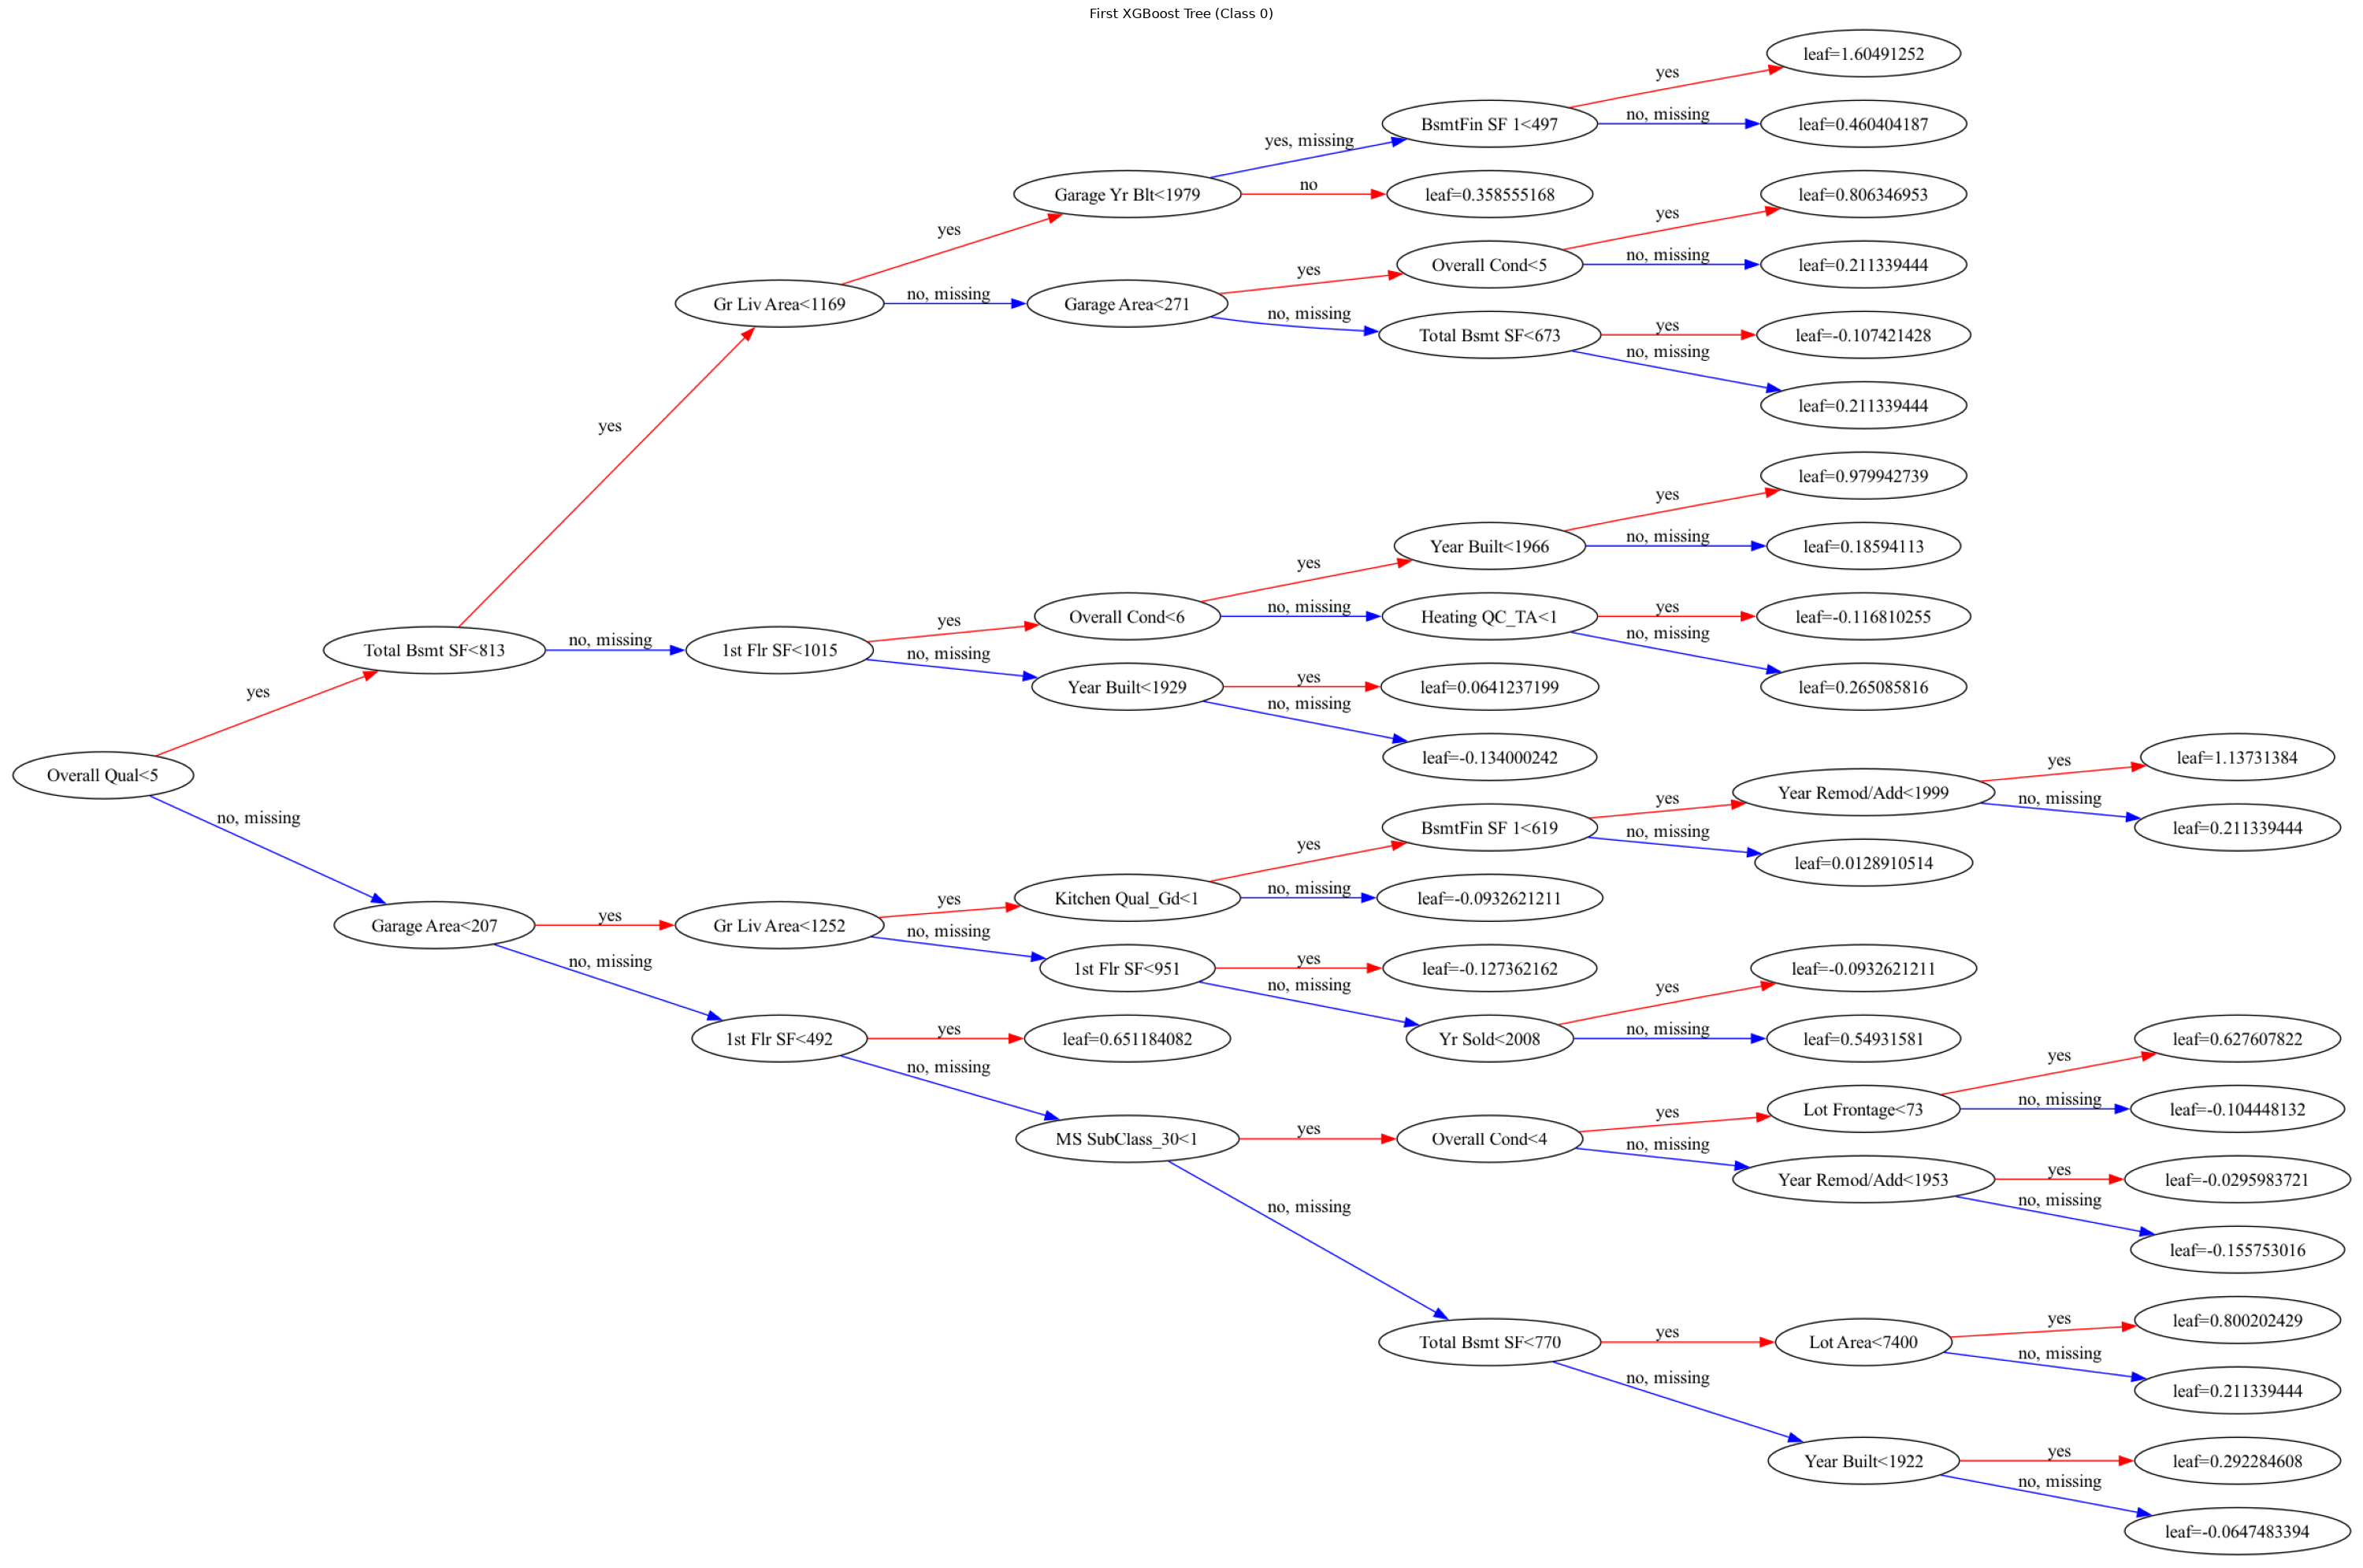

In [12]:
import matplotlib.pyplot as plt
from xgboost import plot_tree

fig, ax = plt.subplots(figsize=(35, 20))

plot_tree(
    baseline,
    num_trees=0,
    rankdir="LR",
    ax=ax
)

ax.set_title("First XGBoost Tree (Class 0)")
plt.tight_layout()
plt.show()

## Train a model with early stopping

In [13]:
from sklearn.model_selection import train_test_split

# Create an internal validation split from the training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

# Train a separate model with early stopping
tree_model = XGBClassifier(
    random_state=42,
    n_estimators=1000,
    eval_metric="mlogloss",
    early_stopping_rounds=30
)

tree_model.fit(
    X_fit,
    y_fit,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Best iteration:", tree_model.best_iteration)
print("Best validation loss:", tree_model.best_score)

Best iteration: 22
Best validation loss: 0.6249752218104295


## Visualize the best tree

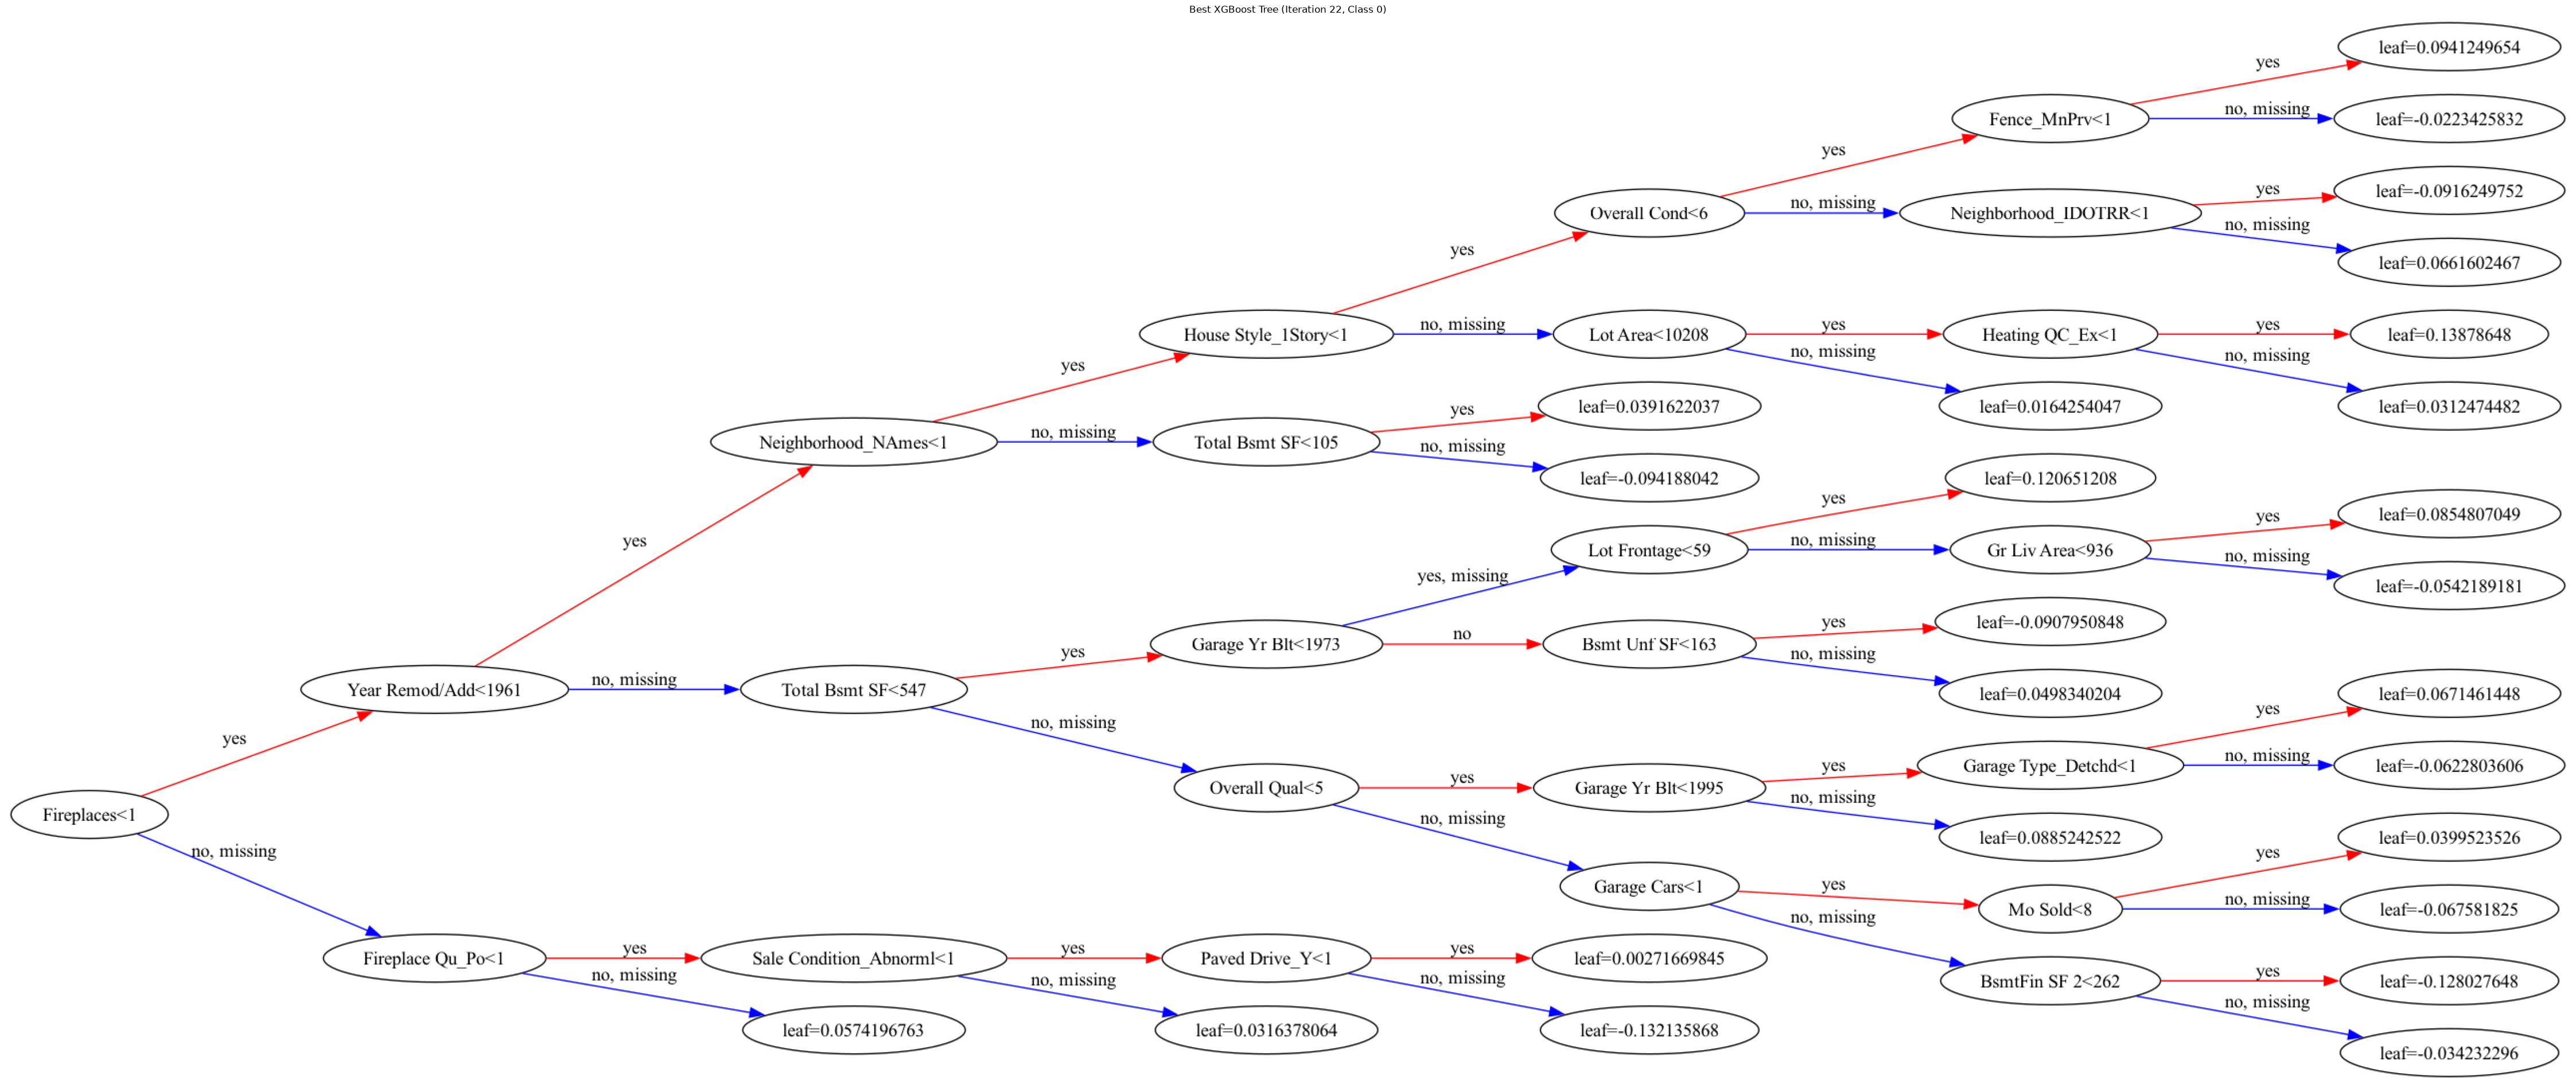

In [14]:
import matplotlib.pyplot as plt
from xgboost import plot_tree

# Find the index of the first tree in the best boosting iteration
best_tree_idx = tree_model.best_iteration * len(CLASS_NAMES)

fig, ax = plt.subplots(figsize=(45, 25))

plot_tree(
    tree_model,
    tree_idx=best_tree_idx,
    rankdir="LR",
    ax=ax
)

ax.set_title(
    f"Best XGBoost Tree (Iteration {tree_model.best_iteration}, Class 0)"
)

plt.tight_layout()

# Save a high-resolution version so you can zoom in
fig.savefig("best_xgboost_tree.png", dpi=300, bbox_inches="tight")

plt.show()



## 10. Feature Importance

Next, I want to see which features have the greatest influence on the model. For this, I compare two different feature importance measurements provided by XGBoost.

- **Gain:** Measures how much a feature contributes to improving the predictions when it is used in a split. A higher gain means that the feature provides more information for the model.
- **Split:** Counts how often a feature is used in the decision trees. A feature can be used frequently without necessarily contributing a lot to the predictions.

I compare the top features according to both measurements to see whether the most frequently used features are also the ones that contribute the most to the model.


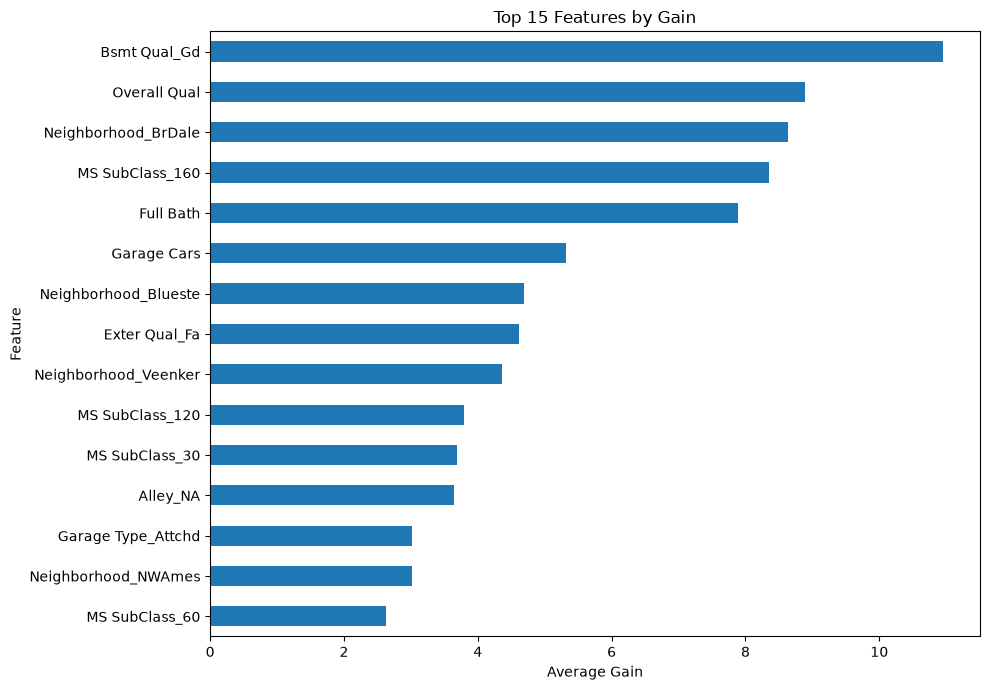

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

booster = baseline.get_booster()

# Feature importance based on gain
gain_importance = pd.Series(
    booster.get_score(importance_type="gain")
).sort_values(ascending=False)

top_gain = gain_importance.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_gain.plot(kind="barh")
plt.xlabel("Average Gain")
plt.ylabel("Feature")
plt.title("Top 15 Features by Gain")
plt.tight_layout()
plt.show()

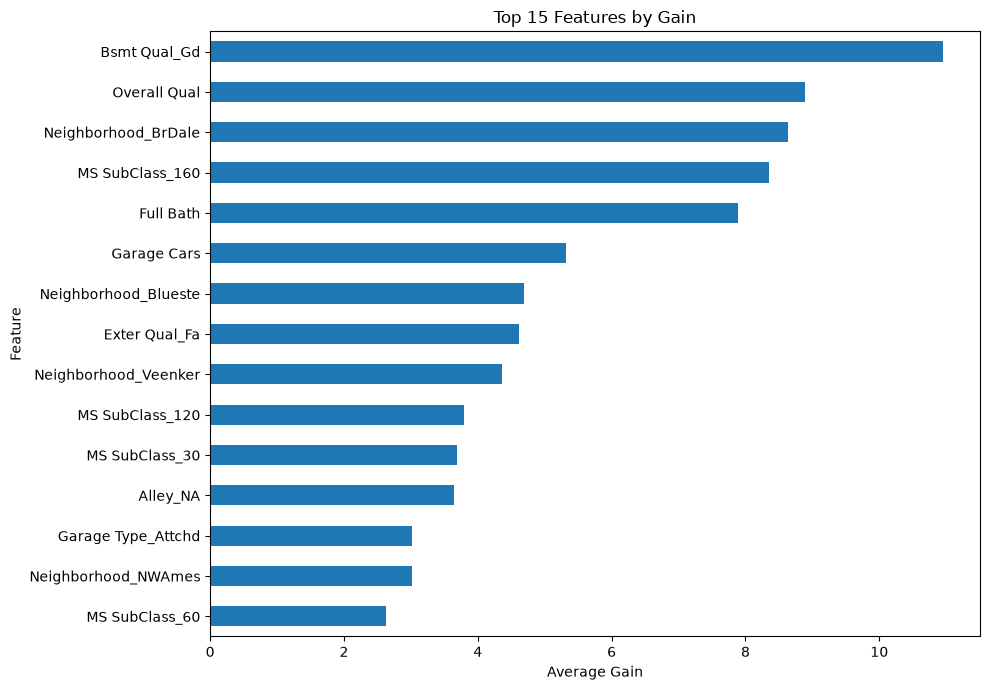

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

booster = baseline.get_booster()

# Feature importance based on gain
gain_importance = pd.Series(
    booster.get_score(importance_type="gain")
).sort_values(ascending=False)

top_gain = gain_importance.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_gain.plot(kind="barh")
plt.xlabel("Average Gain")
plt.ylabel("Feature")
plt.title("Top 15 Features by Gain")
plt.tight_layout()
plt.show()

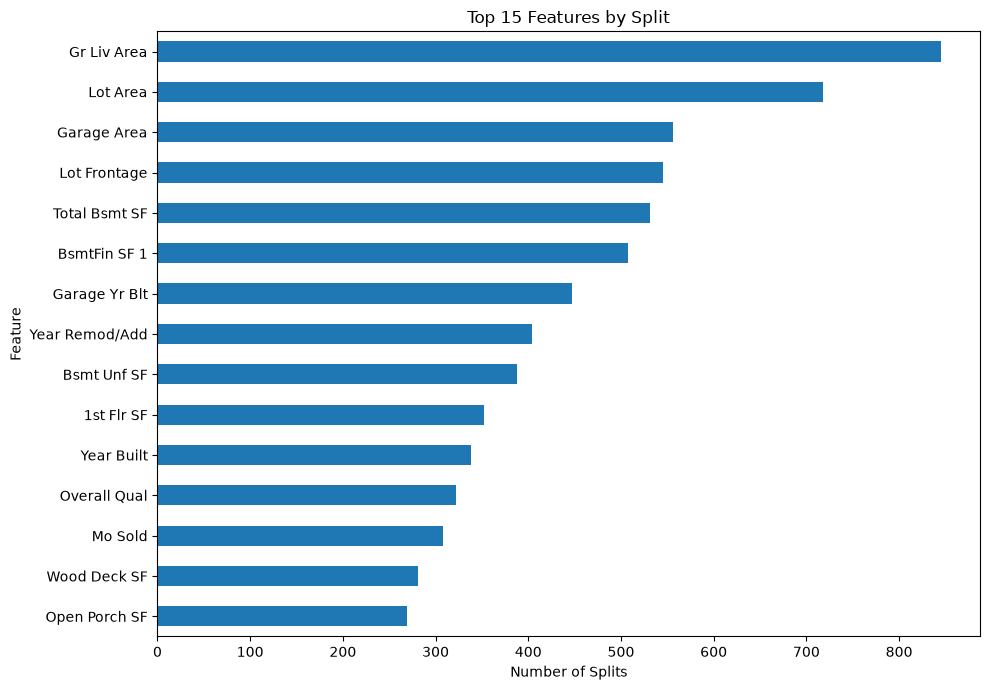

In [17]:
# Feature importance based on the number of splits
split_importance = pd.Series(
    booster.get_score(importance_type="weight")
).sort_values(ascending=False)

top_split = split_importance.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_split.plot(kind="barh")
plt.xlabel("Number of Splits")
plt.ylabel("Feature")
plt.title("Top 15 Features by Split")
plt.tight_layout()
plt.show()

## Feature Engineering Experiments

I want to investigate whether the engineered features from Lab 1 improve the performance of the baseline XGBoost model.

I will compare the original dataset with different combinations of engineered features.

I will use:
- The same stratified 80/20 train-test split.
- Stratified 5-fold cross-validation on the training set.
- The same XGBoost model parameters.
- Macro-F1 as the primary evaluation metric.

This allows me to compare the results while keeping the other experimental conditions unchanged.

In [19]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

from lab2_utils import get_data, get_split, ENGINEERED_FEATURES

In [20]:
experiments = {
    "Baseline": None,

    "HouseAge": ["HouseAge"],

    "YearsSinceRemodel": ["YearsSinceRemodel"],

    "WasRemodeled": ["WasRemodeled"],

    "TotalArea": ["TotalArea"],

    "TotalBathrooms": ["TotalBathrooms"],

    "TotalArea + TotalBathrooms": [
        "TotalArea",
        "TotalBathrooms"
    ],

    "All five features": ENGINEERED_FEATURES
}

In [21]:
# Use exactly the same cross-validation configuration
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
fold_results = {}

for name, selected_features in experiments.items():

    # Load the original or extended dataset
    X, y = get_data(engineered_features=selected_features)

    # Use the same fixed 80/20 split
    X_train, _, y_train, _ = get_split(X, y)

    # Train and evaluate the same XGBoost model
    model = XGBClassifier(random_state=42)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv5,
        scoring="f1_macro"
    )

    # Store individual fold scores
    fold_results[name] = scores

    # Store mean and standard deviation
    results.append({
        "Experiment": name,
        "Mean CV Macro-F1": scores.mean(),
        "Std CV Macro-F1": scores.std()
    })

    print(
        f"{name}: {scores.mean():.3f} "
        f"+/- {scores.std():.3f}"
    )

Baseline: 0.722 +/- 0.020
HouseAge: 0.736 +/- 0.017
YearsSinceRemodel: 0.725 +/- 0.021
WasRemodeled: 0.719 +/- 0.009
TotalArea: 0.737 +/- 0.032
TotalBathrooms: 0.731 +/- 0.012
TotalArea + TotalBathrooms: 0.736 +/- 0.035
All five features: 0.731 +/- 0.023


In [22]:
results_df = pd.DataFrame(results)

# Calculate the difference compared with the original baseline
baseline_score = results_df.loc[
    results_df["Experiment"] == "Baseline",
    "Mean CV Macro-F1"
].iloc[0]

results_df["Difference vs Baseline"] = (
    results_df["Mean CV Macro-F1"] - baseline_score
)

results_df = results_df.sort_values(
    by="Mean CV Macro-F1",
    ascending=False
)

display(results_df.round(4))

,Experiment,Mean CV Macro-F1,Std CV Macro-F1,Difference vs Baseline
4,TotalArea,0.7373,0.0316,0.0149
1,HouseAge,0.7360,0.0168,0.0135
6,TotalArea + TotalBathrooms,0.7359,0.0345,0.0134
7,All five features,0.7312,0.0234,0.0087
5,TotalBathrooms,0.7312,0.0120,0.0087
2,YearsSinceRemodel,0.7255,0.0207,0.0030
0,Baseline,0.7225,0.0196,0.0000
3,WasRemodeled,0.7191,0.0091,-0.0034


In [23]:
experiments = {
    "Baseline": None,

    # Best individual features
    "TotalArea": ["TotalArea"],
    "HouseAge": ["HouseAge"],
    "TotalBathrooms": ["TotalBathrooms"],

    # Combinations of the best-performing features
    "TotalArea + HouseAge": [
        "TotalArea",
        "HouseAge"
    ],

    "TotalArea + TotalBathrooms": [
        "TotalArea",
        "TotalBathrooms"
    ],

    "HouseAge + TotalBathrooms": [
        "HouseAge",
        "TotalBathrooms"
    ],

    # All three best features together
    "Top three features": [
        "TotalArea",
        "HouseAge",
        "TotalBathrooms"
    ]
}

In [24]:
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, selected_features in experiments.items():

    X, y = get_data(engineered_features=selected_features)

    X_train, _, y_train, _ = get_split(X, y)

    model = XGBClassifier(random_state=42)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv5,
        scoring="f1_macro"
    )

    results.append({
        "Experiment": name,
        "Mean CV Macro-F1": scores.mean(),
        "Std CV Macro-F1": scores.std()
    })

    print(f"{name}: {scores.mean():.3f} +/- {scores.std():.3f}")

Baseline: 0.722 +/- 0.020
TotalArea: 0.737 +/- 0.032
HouseAge: 0.736 +/- 0.017
TotalBathrooms: 0.731 +/- 0.012
TotalArea + HouseAge: 0.733 +/- 0.027
TotalArea + TotalBathrooms: 0.736 +/- 0.035
HouseAge + TotalBathrooms: 0.717 +/- 0.014
Top three features: 0.737 +/- 0.029


In [25]:
results_df = pd.DataFrame(results)

baseline_score = results_df.loc[
    results_df["Experiment"] == "Baseline",
    "Mean CV Macro-F1"
].iloc[0]

results_df["Difference vs Baseline"] = (
    results_df["Mean CV Macro-F1"] - baseline_score
)

results_df = results_df.sort_values(
    by="Mean CV Macro-F1",
    ascending=False
)

display(results_df.round(4))

,Experiment,Mean CV Macro-F1,Std CV Macro-F1,Difference vs Baseline
7,Top three features,0.7374,0.0289,0.0150
1,TotalArea,0.7373,0.0316,0.0149
2,HouseAge,0.7360,0.0168,0.0135
5,TotalArea + TotalBathrooms,0.7359,0.0345,0.0134
4,TotalArea + HouseAge,0.7333,0.0267,0.0108
3,TotalBathrooms,0.7312,0.0120,0.0087
0,Baseline,0.7225,0.0196,0.0000
6,HouseAge + TotalBathrooms,0.7167,0.0135,-0.0058



## 12.1 Outlier Removal

In Lab 1, I identified five houses with more than 4,000 sqft of above-ground living area. Three were unfinished houses sold before construction was completed, while the other two were unusually large and expensive houses.

I want to investigate whether removing these observations improves the classification model.

However, I need to keep in mind that two of these houses are expensive properties, so removing them also affects the already-small ≥400k price class.

I compare the macro-F1 score using the same stratified 5-fold cross-validation.


In [30]:
from lab2_utils import (
    load_data,
    clean_data,
    encode_features,
    make_target,
    get_split
)

# Load and clean the original dataset
df_clean = clean_data(load_data())

# Remove houses with more than 4,000 sqft of living area
df_no_outliers = df_clean[
    df_clean["Gr Liv Area"] <= 4000
].copy()

print("Original dataset:", len(df_clean))
print("Dataset without outliers:", len(df_no_outliers))
print("Removed houses:", len(df_clean) - len(df_no_outliers))

Original dataset: 2930
Dataset without outliers: 2925
Removed houses: 5


In [31]:
# Prepare original features without engineered features
X_no_outliers = encode_features(df_no_outliers)
y_no_outliers = make_target(df_no_outliers)

# Use the same train-test split
X_train, X_test, y_train, y_test = get_split(
    X_no_outliers,
    y_no_outliers
)

# Evaluate using the existing cv5
model = XGBClassifier(random_state=42)

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv5,
    scoring="f1_macro"
)

print(f"Mean CV Macro-F1: {scores.mean():.4f}")
print(f"Std CV Macro-F1: {scores.std():.4f}")

Mean CV Macro-F1: 0.7290
Std CV Macro-F1: 0.0190



## 12.2 Handling Missing Values

In the original data preparation, the remaining numerical missing values are left as NaN because XGBoost can handle missing values natively.

I want to compare this approach with median imputation, where missing numerical values are replaced by the median of the corresponding feature.

I use a pipeline so that the median values are calculated separately within each training fold. This prevents information from the validation fold from being used during preprocessing.


In [27]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Model with median imputation
imputed_model = make_pipeline(
    SimpleImputer(strategy="median"),
    XGBClassifier(random_state=42)
)

imputed_scores = cross_val_score(
    imputed_model,
    X_train,
    y_train,
    cv=cv5,
    scoring="f1_macro"
)

print("Native missing values:", round(cv_scores.mean(), 3))
print("Median imputation:", round(imputed_scores.mean(), 3))
print("Imputation standard deviation:", round(imputed_scores.std(), 3))

Native missing values: 0.722
Median imputation: 0.735
Imputation standard deviation: 0.03



## 12.3 Ordinal vs. One-Hot Encoding

In the baseline model, all categorical features are encoded using one-hot encoding.

However, some categorical features describe quality levels that already have a natural order, such as Poor, Fair, Typical, Good and Excellent.

For these features, I want to investigate whether ordinal encoding, where each category is represented by a number according to its order, performs better than one-hot encoding.

I keep the remaining nominal features one-hot encoded, since they do not have a meaningful order.


In [33]:
# Encode the features
X_ordinal = encode_features(df_ordinal)

# Create the target variable
y_ordinal = make_target(df_ordinal)

# Train-test split
X_ordinal_train, _, y_ordinal_train, _ = get_split(
    X_ordinal,
    y_ordinal
)

# Cross-validation
ordinal_scores = cross_val_score(
    XGBClassifier(random_state=42),
    X_ordinal_train,
    y_ordinal_train,
    cv=cv5,
    scoring="f1_macro"
)

print(f"Ordinal encoding: {ordinal_scores.mean():.4f} +/- {ordinal_scores.std():.4f}")

Ordinal encoding: 0.7312 +/- 0.0159


In [35]:
# Use the original cleaned dataset
X_onehot = encode_features(df_clean)
y_onehot = make_target(df_clean)

# Train-test split
X_onehot_train, _, y_onehot_train, _ = get_split(
    X_onehot,
    y_onehot
)

# Cross-validation using your existing cv5
onehot_scores = cross_val_score(
    XGBClassifier(random_state=42),
    X_onehot_train,
    y_onehot_train,
    cv=cv5,
    scoring="f1_macro"
)

print(
    f"One-hot encoding: {onehot_scores.mean():.4f} "
    f"+/- {onehot_scores.std():.4f}"
)

One-hot encoding: 0.7225 +/- 0.0196



## 13. Handling Imbalanced Classes

As seen in the beginning, the six price classes are not equally represented in the dataset. The ≥400k class has only 64 houses, while the 130–180k class has 1,037.

Although macro-F1 gives every class equal importance during evaluation, the model is not automatically trained with equal importance for every class.

I want to investigate whether balancing the training data can improve the predictions, especially for the smaller classes.

I compare two approaches:

- **Balanced sample weights:** Each training observation receives a weight based on the frequency of its class. Observations from smaller classes receive higher weights, so errors on these examples have a greater influence during training.
- **Random oversampling:** Houses from the smaller classes are randomly selected with replacement until all classes have the same number of observations.

I compare both approaches with the original baseline using stratified 5-fold cross-validation. Balancing is performed only on the training folds, so the validation data remains unchanged.


In [29]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils import resample

def evaluate_imbalance_method(method):

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        cv5.split(X_train, y_train)
    ):

        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]

        X_fold_val = X_train.iloc[val_idx]
        y_fold_val = y_train.iloc[val_idx]

        model = XGBClassifier(random_state=42)

        if method == "weights":

            # Give more weight to observations from smaller classes
            weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )

            model.fit(
                X_fold_train,
                y_fold_train,
                sample_weight=weights
            )

        elif method == "oversampling":

            # Balance the classes by randomly duplicating observations
            max_count = y_fold_train.value_counts().max()

            X_parts = []
            y_parts = []

            for class_label in sorted(y_fold_train.unique()):

                positions = np.where(
                    y_fold_train.to_numpy() == class_label
                )[0]

                sampled_positions = resample(
                    positions,
                    replace=True,
                    n_samples=max_count,
                    random_state=42 + fold
                )

                X_parts.append(X_fold_train.iloc[sampled_positions])
                y_parts.append(y_fold_train.iloc[sampled_positions])

            X_balanced = pd.concat(X_parts)
            y_balanced = pd.concat(y_parts)

            model.fit(X_balanced, y_balanced)

        # Evaluate on the original, unchanged validation fold
        y_val_pred = model.predict(X_fold_val)

        fold_scores.append(
            f1_score(
                y_fold_val,
                y_val_pred,
                average="macro"
            )
        )

    return np.array(fold_scores)


# Compare the two approaches
weight_scores = evaluate_imbalance_method("weights")
oversampling_scores = evaluate_imbalance_method("oversampling")

imbalance_results = pd.DataFrame([
    {
        "Strategy": "Original baseline",
        "Mean macro-F1": cv_scores.mean(),
        "Std": cv_scores.std()
    },
    {
        "Strategy": "Balanced sample weights",
        "Mean macro-F1": weight_scores.mean(),
        "Std": weight_scores.std()
    },
    {
        "Strategy": "Random oversampling",
        "Mean macro-F1": oversampling_scores.mean(),
        "Std": oversampling_scores.std()
    }
])

display(imbalance_results.round(3))

,Strategy,Mean macro-F1,Std
0,Original baseline,0.722,0.020
1,Balanced sample weights,0.745,0.021
2,Random oversampling,0.732,0.008



## 14. Comparison and Conclusions

After evaluating the baseline model and experimenting with different data preparation and class balancing strategies, I compare the results using macro-F1 and its standard deviation from cross-validation.

The main things I want to investigate are:

- Whether the engineered features from Lab 1 improve the classification performance.
- Whether removing outliers or imputing missing values makes a difference.
- Whether ordinal encoding works better than one-hot encoding for quality-related features.
- Whether balanced sample weights or random oversampling improve the predictions for the smaller classes.

I also compare the results with the original baseline to see whether the changes lead to a meaningful improvement.

Since Ina's previous experiments showed that differences of approximately 0.01 can be caused by the random distribution of houses between folds, I do not consider such small differences automatically meaningful.

Finally, I look at the individual class metrics to see whether an improvement in macro-F1 also means better predictions for the minority classes.


I want a model with:\
stratified sampling 8-%-20%,\
stratifies 5 fold cv,\
outliers remove them,\ 
missing values should use median imputation,\
encoding: ordinal did better than one-hot, so use ordinal\
add the top3features   "Top three features": [\
        "TotalArea",\
        "HouseAge",\
        "TotalBathrooms"/
    ]\
,should be balanced sample weights\